# 06 · Optimización, ensambles, generalización y selección del modelo final

**Evaluación Final Transversal — MLY1101 · Caso C: Spotify Tracks**

Este notebook cubre las etapas que se agregaron al proyecto para la evaluación final:

| Sección | Pregunta | Pipeline Kedro |
|---|---|---|
| 1. Optimización de hiperparámetros | ¿La búsqueda sistemática mejora la configuración inicial de cada modelo? | `hyperparameter_tuning` |
| 2. Técnicas de ensamble | ¿Combinar modelos de distinta familia mejora al mejor modelo individual? | `ensembles` |
| 3. Capacidad de generalización | ¿Los modelos rinden igual con canciones que nunca vieron? | `evaluation` |
| 4. Sesgo del modelo por género | ¿El modelo se equivoca más con algunos géneros? | (este notebook) |
| 5. Selección de la solución óptima | ¿Qué modelo se despliega y por qué? | (este notebook) |

> Carga los resultados de `kedro run` (o del notebook `00_reproducir_proyecto`); no reentrena.

In [1]:
%load_ext kedro.ipython

The kedro.ipython extension is already loaded. To reload it, use:
  %reload_ext kedro.ipython


In [2]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Image, display

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 90
pd.set_option("display.max_colwidth", 120)

PLOTS = "../results/plots"
MODELS = Path("../models/trained_models")

## 1. Optimización de hiperparámetros

En la EP2 solo se optimizó Gradient Boosting; Logistic Regression, Ridge y Random Forest usaban valores elegidos a mano.
Ahora **los 6 modelos** pasan por una búsqueda con validación cruzada y se comparan contra su configuración inicial
**con exactamente los mismos folds**:

| Modelo | Estrategia | Espacio de búsqueda | Por qué esta estrategia |
|---|---|---|---|
| Logistic Regression | `GridSearchCV` | `C` ∈ {0.01, 0.1, 1, 10, 100} | Un solo hiperparámetro: se prueba todo |
| Ridge | `GridSearchCV` | `alpha` ∈ {0.01 … 300} | Un solo hiperparámetro: se prueba todo |
| Random Forest | `RandomizedSearchCV` (8 combinaciones) | `max_depth`, `min_samples_leaf`, `max_features` (27 combinaciones) | Cada ajuste es caro (~10–20 s); muestrear es suficiente |
| Gradient Boosting | `RandomizedSearchCV` (15 combinaciones) | `learning_rate`, `max_iter`, `max_leaf_nodes`, `min_samples_leaf`, `l2_regularization` (432 combinaciones) | Espacio grande con interacciones; un grid completo costaría ~30× más |

- **Métrica optimizada:** F1 en clasificación (desbalance 73/27) y MAE en regresión (error en puntos, la más fácil de explicar al negocio).
- **Validación:** 3 folds (estratificados en clasificación) sobre train. El test nunca se usa para elegir hiperparámetros.
- **Regla de seguridad:** si la búsqueda no supera a la configuración inicial, se conserva la inicial.

In [3]:
tuning_clf = catalog.load("tuning_summary_clf")
tuning_clf

                    INFO     Loading data from tuning_summary_clf (CSVDataset)...              ]8;id=365126;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=365127;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

,Modelo,Busqueda,Metrica_CV,Inicial,Optimizado,Mejora,Mejora_pct,Modelo_final,Mejores_parametros
0,LogisticRegression,GridSearchCV (5 combinaciones),f1,0.6430,0.6430,0.0000,0.00,optimizado,{'C': 100.0}
1,RandomForest,RandomizedSearchCV (8 combinaciones),f1,0.6078,0.6213,0.0135,2.22,optimizado,"{'min_samples_leaf': 3, 'max_features': 0.2, 'max_depth': 30}"
2,GradientBoosting,RandomizedSearchCV (15 combinaciones),f1,0.6598,0.6708,0.0110,1.66,optimizado,"{'min_samples_leaf': 50, 'max_leaf_nodes': 127, 'max_iter': 200, 'learning_rate': 0.05, 'l2_regularization': 1.0}"


In [4]:
tuning_reg = catalog.load("tuning_summary_reg")
tuning_reg

                    INFO     Loading data from tuning_summary_reg (CSVDataset)...              ]8;id=365132;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=365133;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

,Modelo,Busqueda,Metrica_CV,Inicial,Optimizado,Mejora,Mejora_pct,Modelo_final,Mejores_parametros
0,Ridge,GridSearchCV (6 combinaciones),MAE,9.2845,9.2783,0.0061,0.07,optimizado,{'alpha': 0.01}
1,RandomForest,RandomizedSearchCV (8 combinaciones),MAE,10.8409,9.9989,0.8420,7.77,optimizado,"{'min_samples_leaf': 3, 'max_features': 0.3, 'max_depth': 30}"
2,GradientBoosting,RandomizedSearchCV (15 combinaciones),MAE,9.1499,8.8999,0.2500,2.73,optimizado,"{'min_samples_leaf': 50, 'max_leaf_nodes': 127, 'max_iter': 800, 'learning_rate': 0.05, 'l2_regularization': 0.0}"


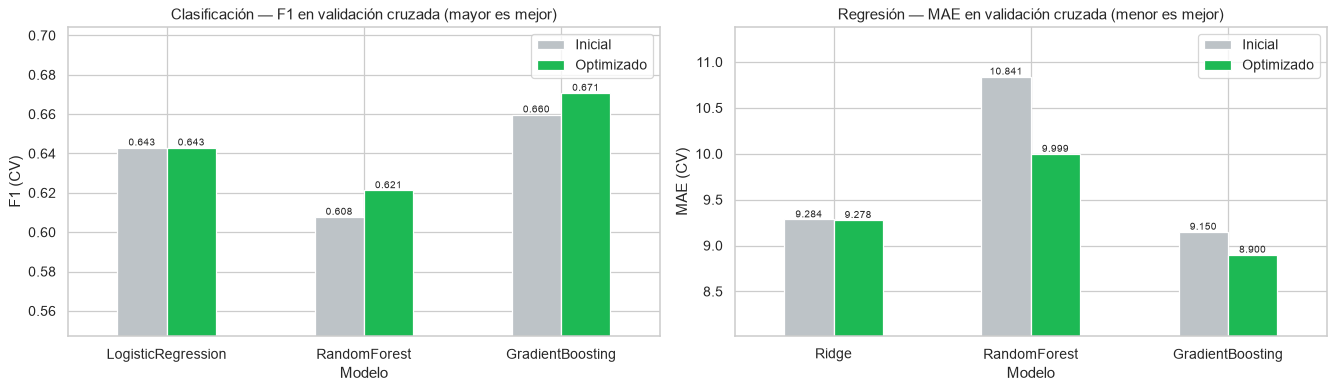

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, df, label, title in [
    (axes[0], tuning_clf, "F1 (CV)", "Clasificación — F1 en validación cruzada (mayor es mejor)"),
    (axes[1], tuning_reg, "MAE (CV)", "Regresión — MAE en validación cruzada (menor es mejor)"),
]:
    df.set_index("Modelo")[["Inicial", "Optimizado"]].plot.bar(ax=ax, rot=0, color=["#BDC3C7", "#1DB954"])
    ax.set_ylabel(label)
    ax.set_title(title)
    for container in ax.containers:
        ax.bar_label(container, fmt="%.3f", fontsize=8)
    lo, hi = df[["Inicial", "Optimizado"]].values.min(), df[["Inicial", "Optimizado"]].values.max()
    ax.set_ylim(lo * 0.9, hi * 1.05)
plt.tight_layout()
plt.show()

In [6]:
# Detalle de la búsqueda de Gradient Boosting: ¿qué tan sensible es a los hiperparámetros?
hp = catalog.load("hyperparameter_results_clf")
print(f"F1 de las 15 combinaciones: mín {hp['mean_test_score'].min():.4f} · máx {hp['mean_test_score'].max():.4f}")
hp.head(5)

[11/23/26 23:08:31] INFO     Loading data from hyperparameter_results_clf (CSVDataset)...      ]8;id=365138;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=365139;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

F1 de las 15 combinaciones: mín 0.6424 · máx 0.6708


,rank_test_score,mean_test_score,std_test_score,mean_fit_time,params
0,1,0.670753,0.003568,10.114640,"{'min_samples_leaf': 50, 'max_leaf_nodes': 127, 'max_iter': 200, 'learning_rate': 0.05, 'l2_regularization': 1.0}"
1,2,0.670705,0.002036,17.612729,"{'min_samples_leaf': 20, 'max_leaf_nodes': 127, 'max_iter': 200, 'learning_rate': 0.03, 'l2_regularization': 0.1}"
2,3,0.669991,0.001349,20.962019,"{'min_samples_leaf': 50, 'max_leaf_nodes': 127, 'max_iter': 200, 'learning_rate': 0.03, 'l2_regularization': 0.1}"
3,4,0.669479,0.003514,16.089946,"{'min_samples_leaf': 50, 'max_leaf_nodes': 127, 'max_iter': 800, 'learning_rate': 0.05, 'l2_regularization': 0.0}"
4,5,0.668233,0.001399,21.495332,"{'min_samples_leaf': 20, 'max_leaf_nodes': 63, 'max_iter': 800, 'learning_rate': 0.03, 'l2_regularization': 0.0}"


**Lectura de la optimización:**

- La búsqueda **igualó o mejoró** a los 6 modelos; en ningún caso hubo que conservar la configuración inicial.
- **Logistic Regression** no mejora: `C=100` y `C=1` empatan (F1 0.6430). Con 61 mil canciones y 144 variables, la regularización casi no influye.
- **Ridge** mejora solo 0.07%: igual que en clasificación, el modelo lineal ya estaba en su techo.
- **Random Forest** es el que más gana: **+2.2% de F1 y −7.8% de MAE**, con árboles más profundos (`max_depth=30`) y hojas más chicas (`min_samples_leaf=3`). La configuración inicial de la EP2 lo estaba limitando.
- **Gradient Boosting** mejora **+1.7% de F1 y −2.7% de MAE** frente a los valores por defecto de scikit-learn. Las mejores combinaciones usan muchas hojas (127), pero con al menos 50 canciones cada una: complejidad para capturar las interacciones género × audio sin memorizar.
- Las 5 mejores combinaciones de Gradient Boosting tienen F1 entre 0.668 y 0.671: el modelo es **robusto** a la elección exacta de hiperparámetros.

## 2. Técnicas de ensamble

Un ensamble combina varios modelos para obtener uno mejor que cada uno por separado. El proyecto usa **cuatro técnicas**:

| Técnica | Modelo | Cómo combina | Qué reduce |
|---|---|---|---|
| **Bagging** | Random Forest | 200 árboles, cada uno entrenado con una muestra bootstrap distinta y un subconjunto de variables; se promedian | Varianza (un árbol solo sobreajusta) |
| **Boosting** | Gradient Boosting | Árboles secuenciales: cada uno se entrena sobre los errores del anterior | Sesgo (aprende patrones que un modelo simple no ve) |
| **Voting** | `VotingClassifier` / `VotingRegressor` | Promedia las predicciones de los 3 modelos optimizados (en clasificación, voto *soft*: promedia probabilidades) | Errores no correlacionados entre modelos |
| **Stacking** | `StackingClassifier` / `StackingRegressor` | Un meta-modelo (Logistic Regression / RidgeCV) aprende **cuánto confiar** en cada modelo base, usando predicciones *out-of-fold* | Igual que Voting, pero con pesos aprendidos en vez de iguales |

Los tres modelos base son de **familias distintas** (lineal, bagging y boosting): un ensamble solo mejora si sus miembros
se equivocan en canciones diferentes.

In [7]:
clf = catalog.load("clf_test_metrics")
clf.style.highlight_max(subset=["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"], color="#C8F7C5").format(precision=4)

                    INFO     Loading data from clf_test_metrics (CSVDataset)...                ]8;id=365144;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=365145;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

,Modelo,Accuracy,Precision,Recall,F1,ROC_AUC
0,Baseline,0.7344,0.0000,0.0000,0.0000,0.5000
1,LogisticRegression,0.7641,0.5368,0.8135,0.6468,0.8612
2,RandomForest,0.7377,0.5037,0.8456,0.6313,0.8572
3,GradientBoosting,0.7964,0.5837,0.8131,0.6796,0.8844
4,Voting,0.7828,0.5616,0.8296,0.6698,0.8794
5,Stacking,0.7894,0.5718,0.8246,0.6753,0.8836


In [8]:
reg = catalog.load("reg_test_metrics")
reg.style.highlight_min(subset=["MAE", "RMSE"], color="#C8F7C5").highlight_max(subset=["R2"], color="#C8F7C5").format(precision=3)

                    INFO     Loading data from reg_test_metrics (CSVDataset)...                ]8;id=365150;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=365151;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

,Modelo,MAE,RMSE,R2
0,Baseline,14.882,17.792,-0.000
1,Ridge,9.123,12.547,0.503
2,RandomForest,9.822,13.107,0.457
3,GradientBoosting,8.654,12.134,0.535
4,Voting,9.000,12.296,0.522
5,Stacking,8.629,12.116,0.536


In [9]:
# Aporte de los ensambles frente al mejor modelo individual
def aporte(df, metric, higher_is_better=True):
    individuales = df[~df["Modelo"].isin(["Baseline", "Voting", "Stacking"])].set_index("Modelo")[metric]
    mejor = individuales.idxmax() if higher_is_better else individuales.idxmin()
    filas = []
    for ens in ["Voting", "Stacking"]:
        valor = df.set_index("Modelo").loc[ens, metric]
        delta = (valor - individuales[mejor]) * (1 if higher_is_better else -1)
        filas.append({"Ensamble": ens, "Métrica": metric, "Valor": valor,
                      "Mejor individual": f"{mejor} ({individuales[mejor]:.4f})", "Mejora": delta})
    return filas

pd.DataFrame(aporte(clf, "F1") + aporte(clf, "ROC_AUC") + aporte(reg, "MAE", False) + aporte(reg, "R2")).round(4)

,Ensamble,Métrica,Valor,Mejor individual,Mejora
0,Voting,F1,0.6698,GradientBoosting (0.6796),-0.0098
1,Stacking,F1,0.6753,GradientBoosting (0.6796),-0.0043
2,Voting,ROC_AUC,0.8794,GradientBoosting (0.8844),-0.0050
3,Stacking,ROC_AUC,0.8836,GradientBoosting (0.8844),-0.0008
4,Voting,MAE,8.9998,GradientBoosting (8.6539),-0.3459
5,Stacking,MAE,8.6285,GradientBoosting (8.6539),0.0254
6,Voting,R2,0.5223,GradientBoosting (0.5349),-0.0126
7,Stacking,R2,0.5363,GradientBoosting (0.5349),0.0014


In [10]:
# Pesos que el meta-modelo del Stacking asignó a cada modelo base
weights = catalog.load("stacking_weights")
weights

                    INFO     Loading data from stacking_weights (CSVDataset)...                ]8;id=365156;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=365157;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

,Tarea,Modelo_base,Peso_meta_modelo
0,clasificacion,lineal,0.6478
1,clasificacion,random_forest,1.2878
2,clasificacion,gradient_boosting,4.3652
3,regresion,lineal,0.2459
4,regresion,random_forest,0.0469
5,regresion,gradient_boosting,0.7425


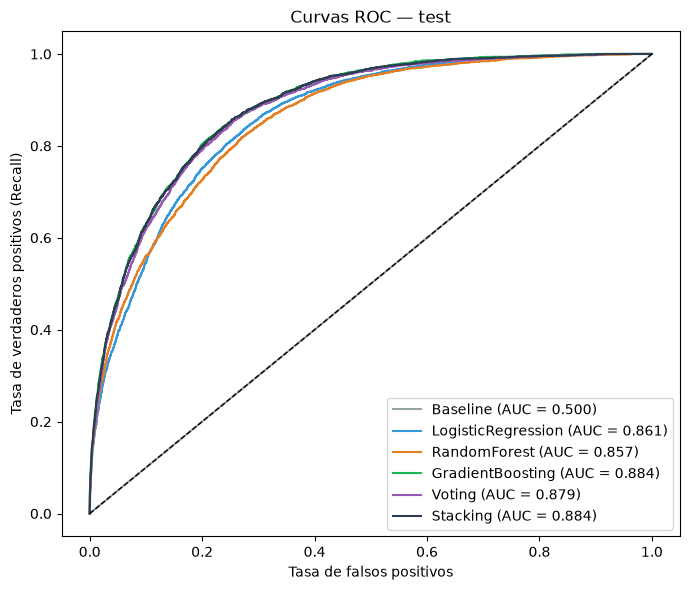

In [11]:
display(Image(f"{PLOTS}/03_clf_roc_curves.png"))

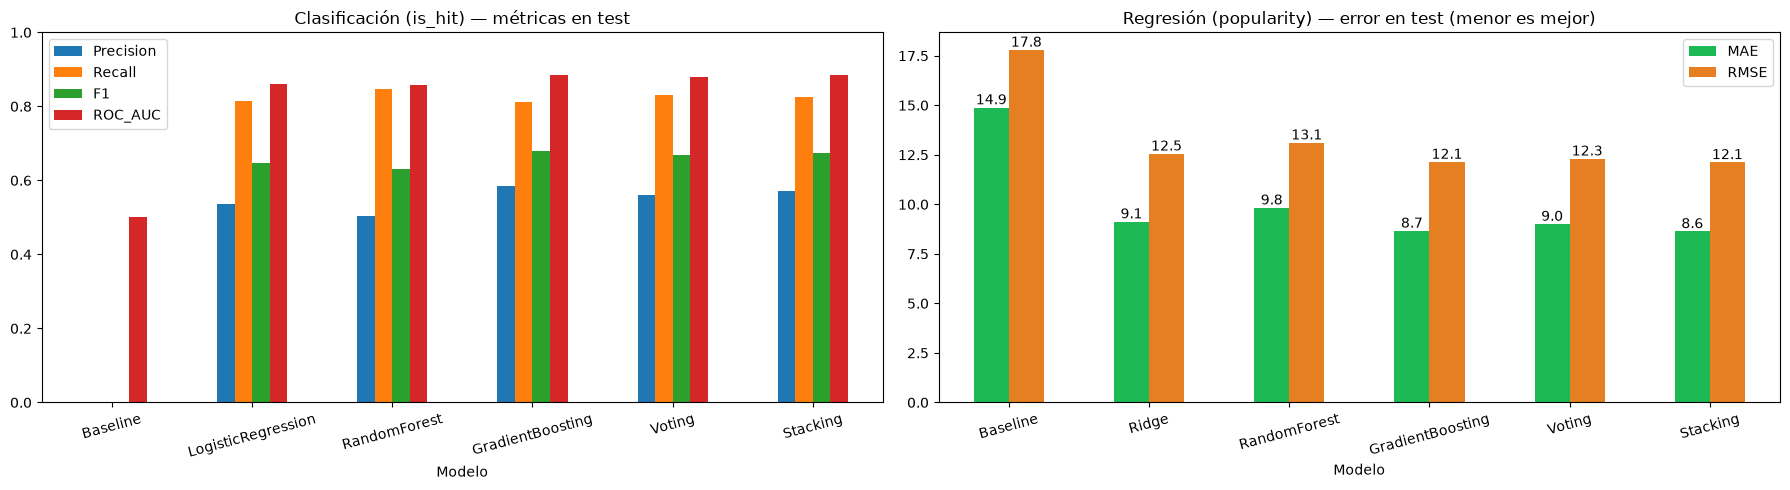

In [12]:
display(Image(f"{PLOTS}/04_metrics_comparison.png"))

**Resultado: los ensambles de segundo nivel no superan a Gradient Boosting.**

| Modelo | F1 test (clasificación) | MAE test (regresión) |
|---|---|---|
| Gradient Boosting | **0.680** | 8.65 |
| Stacking | 0.675 | **8.63** |
| Voting | 0.670 | 9.00 |

- **Voting empeora** frente a Gradient Boosting: promedia por igual al mejor modelo con dos más débiles (Logistic Regression y Random Forest), y eso lo diluye.
- **Stacking empata:** el meta-modelo aprende a confiar casi solo en Gradient Boosting (peso 4.37 contra 1.29 de Random Forest y 0.65 del lineal en clasificación; 0.74 contra 0.05 y 0.25 en regresión). Es la confirmación empírica de que Gradient Boosting ya captura lo que aportan los otros.
- En regresión, Stacking baja el MAE en 0.025 puntos (0.3%), menos que la variación entre folds (±0.05): no es una mejora real.
- **Por qué no ayudan:** los modelos base se equivocan en las mismas canciones. Sus residuos de regresión tienen una correlación de 0.91 a 0.95, y el 85% de los errores de Gradient Boosting también los comete Logistic Regression. Combinar modelos solo corrige errores que no comparten.
- **El aporte del ensamble está en el boosting:** Gradient Boosting, un ensamble secuencial de árboles, mejora al mejor modelo simple de 0.647 a 0.680 de F1 (+5.1%) y de 9.12 a 8.65 de MAE (−5.1%).

## 3. Capacidad de generalización

Un modelo es útil solo si rinde igual con canciones **que nunca vio**. Se compara cada modelo en tres conjuntos:

- **Train:** las canciones con que se entrenó (siempre es el resultado más optimista).
- **Validación cruzada (5 folds):** cada fold se evalúa con un modelo que no lo vio; la desviación estándar mide la estabilidad.
- **Test (20%):** reservado desde el inicio, nunca usado para entrenar ni para elegir hiperparámetros.

Si la diferencia entre train y test es grande, el modelo **memoriza** (sobreajuste). Si CV y test coinciden, la estimación es confiable.

In [13]:
gen_clf = catalog.load("generalization_clf")
gen_clf

                    INFO     Loading data from generalization_clf (CSVDataset)...              ]8;id=365162;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=365163;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

,Modelo,F1_train,F1_cv,F1_test,Brecha_F1,ROC_AUC_train,ROC_AUC_cv,ROC_AUC_test,Diagnostico
0,LogisticRegression,0.6449,0.6428,0.6468,-0.0019,0.8597,0.8580,0.8612,generaliza bien
1,RandomForest,0.7181,0.6208,0.6313,0.0868,0.9439,0.8500,0.8572,sobreajuste leve
2,GradientBoosting,0.7582,0.6728,0.6796,0.0786,0.9382,0.8778,0.8844,sobreajuste leve
3,Voting,0.7184,0.6638,0.6698,0.0486,0.9237,0.8739,0.8794,generaliza bien
4,Stacking,0.7480,0.6687,0.6753,0.0727,0.9376,0.8771,0.8836,generaliza bien


In [14]:
gen_reg = catalog.load("generalization_reg")
gen_reg

                    INFO     Loading data from generalization_reg (CSVDataset)...              ]8;id=365168;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=365169;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

,Modelo,MAE_train,MAE_cv,MAE_test,Brecha_MAE,R2_train,R2_cv,R2_test,Diagnostico
0,Ridge,9.2536,9.2761,9.1228,-0.1308,0.4976,0.4946,0.5026,generaliza bien
1,RandomForest,8.7638,9.9703,9.8225,1.0587,0.5504,0.4507,0.4572,sobreajuste leve
2,GradientBoosting,7.9310,8.8514,8.6539,0.7229,0.6175,0.5228,0.5349,generaliza bien
3,Voting,8.4632,9.1801,8.9998,0.5366,0.5816,0.5130,0.5223,generaliza bien
4,Stacking,8.0797,8.8316,8.6285,0.5488,0.6015,0.5243,0.5363,generaliza bien


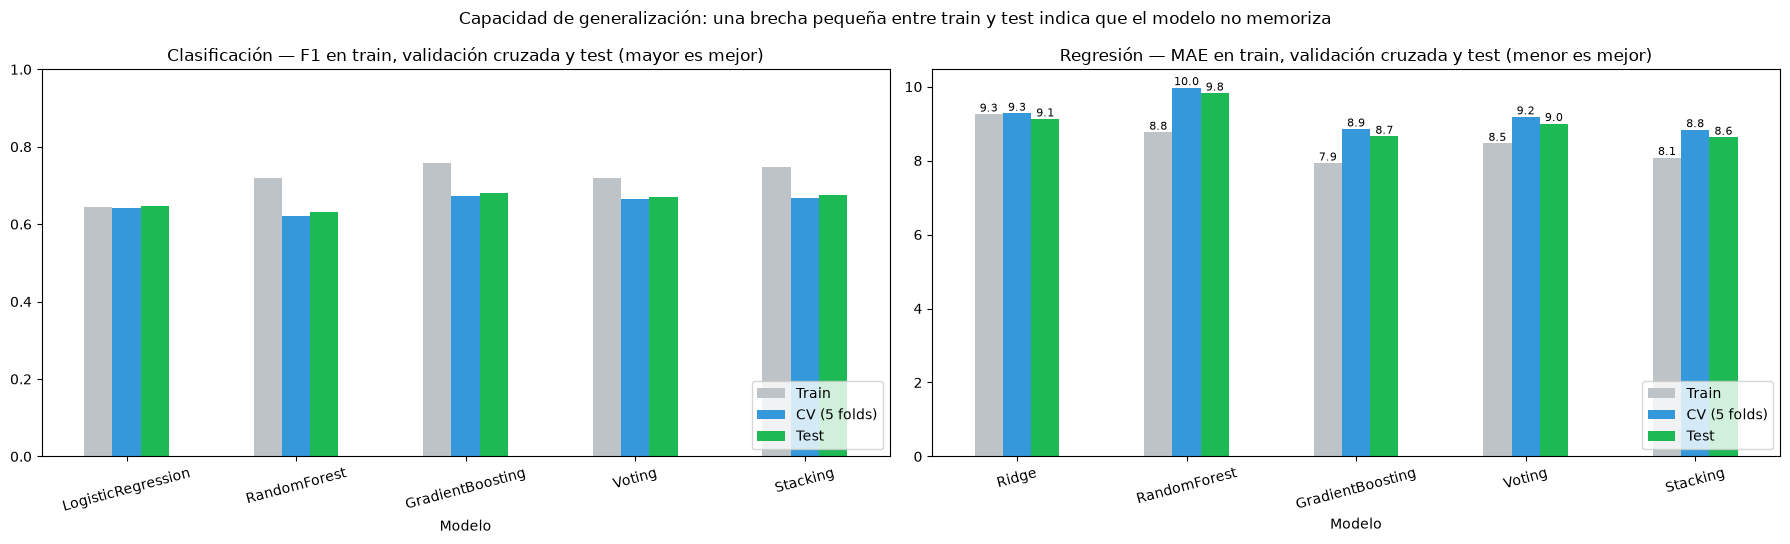

In [15]:
display(Image(f"{PLOTS}/06_generalization.png"))

In [16]:
# Estabilidad entre folds: desviación estándar de la validación cruzada
cv_clf = catalog.load("cv_clf_results")[["Modelo", "f1_mean", "f1_std", "roc_auc_mean", "roc_auc_std"]]
cv_reg = catalog.load("cv_reg_results")[["Modelo", "MAE_mean", "MAE_std", "R2_mean", "R2_std"]]
display(cv_clf)
display(cv_reg)

                    INFO     Loading data from cv_clf_results (CSVDataset)...                  ]8;id=365174;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=365175;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

                    INFO     Loading data from cv_reg_results (CSVDataset)...                  ]8;id=365180;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=365181;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

,Modelo,f1_mean,f1_std,roc_auc_mean,roc_auc_std
0,LogisticRegression,0.6428,0.0028,0.8580,0.0022
1,RandomForest,0.6208,0.0055,0.8500,0.0031
2,GradientBoosting,0.6728,0.0038,0.8778,0.0020
3,Voting,0.6638,0.0046,0.8739,0.0018
4,Stacking,0.6687,0.0044,0.8771,0.0020


,Modelo,MAE_mean,MAE_std,R2_mean,R2_std
0,Ridge,9.2761,0.0516,0.4946,0.0062
1,RandomForest,9.9703,0.0595,0.4507,0.0062
2,GradientBoosting,8.8514,0.0467,0.5228,0.0057
3,Voting,9.1801,0.0474,0.5130,0.0059
4,Stacking,8.8316,0.0478,0.5243,0.0060


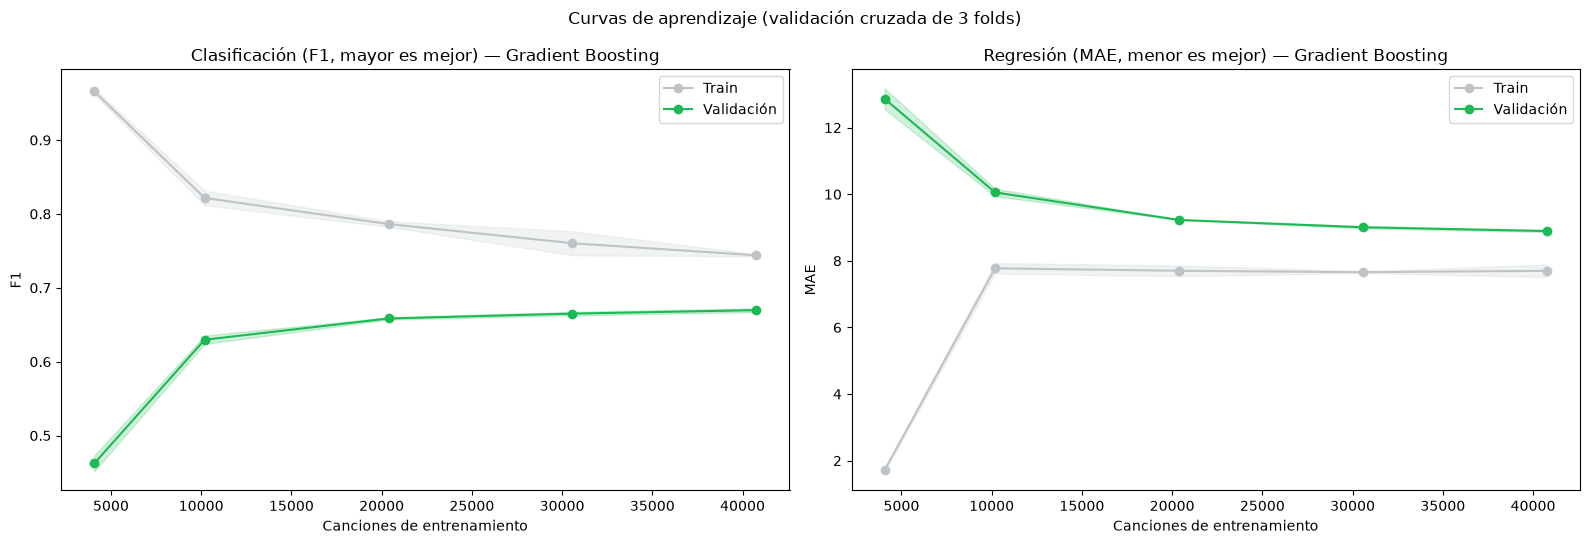

                    INFO     Loading data from learning_curve_results (CSVDataset)...          ]8;id=365186;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=365187;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

,Tarea,Metrica,n_train,train_mean,train_std,val_mean,val_std
0,clasificacion,F1,4076,0.9659,0.0040,0.4623,0.0107
1,clasificacion,F1,10191,0.8216,0.0099,0.6297,0.0056
2,clasificacion,F1,20383,0.7863,0.0038,0.6585,0.0015
3,clasificacion,F1,30575,0.7604,0.0162,0.6651,0.0024
4,clasificacion,F1,40767,0.7440,0.0014,0.6698,0.0027
5,regresion,MAE,4076,1.7241,0.0463,12.8612,0.3141
6,regresion,MAE,10191,7.7754,0.1567,10.0527,0.1136
7,regresion,MAE,20383,7.7010,0.1618,9.2281,0.0053
8,regresion,MAE,30575,7.6586,0.0272,9.0080,0.0321
9,regresion,MAE,40767,7.7006,0.1859,8.8940,0.0309


In [17]:
display(Image(f"{PLOTS}/06_learning_curves.png"))
catalog.load("learning_curve_results")

**Los modelos generalizan: validación cruzada y test coinciden en todos.**

- **CV ≈ test:** Gradient Boosting tiene F1 0.673 en CV y 0.680 en test; MAE 8.85 en CV y 8.65 en test. La desviación entre folds es ≤ 0.006 en F1 y ≤ 0.06 en MAE: el resultado no depende de cómo se partieron los datos.
- **Brecha train → test:** los lineales casi no tienen brecha, porque son demasiado simples para memorizar. Los árboles tienen una brecha leve: Gradient Boosting pasa de F1 0.758 en train a 0.680 en test (10%) y de MAE 7.93 a 8.65 (8%); Random Forest, de 0.718 a 0.631 (12%) y de 8.76 a 9.82 (11%).
- **Diagnóstico:** sobreajuste leve y controlado. Gradient Boosting memoriza algo de train, pero aun así es el mejor en test, y el test no se usó para ninguna decisión.
- **Curvas de aprendizaje:** la curva de validación sube y la de train baja hasta casi juntarse. El F1 de validación pasa de 0.46 con 4 mil canciones a 0.670 con 41 mil, todavía subiendo un poco; el MAE baja de 12.9 a 8.9. Más canciones ayudarían poco: el techo lo ponen las variables que faltan (artista, marketing, fecha de lanzamiento).

## 4. Sesgo del modelo por género

El EDA mostró un **sesgo de recopilación** en los géneros latinos: el dataset tomó copias de recopilatorios en vez de los
originales, así que éxitos mundiales aparecen con popularidad 0–2. Aquí se mide si ese sesgo de los datos **pasa al modelo**:
se comparan las predicciones del modelo final con la realidad, género por género, en el conjunto de test.

In [18]:
X_test = catalog.load("X_test")
y_clf = catalog.load("y_test_clf").squeeze()
y_reg = catalog.load("y_test_reg").squeeze()
modelo_clf = catalog.load("gradient_boosting_clf")
modelo_reg = catalog.load("gradient_boosting_reg")

genre_cols = [c for c in X_test.columns if c.startswith("track_genre_")]
genero = X_test[genre_cols].idxmax(axis=1).str.replace("track_genre_", "")

pred_clf = modelo_clf.predict(X_test)
pred_reg = modelo_reg.predict(X_test)
df = pd.DataFrame({"genero": genero, "hit": y_clf.values, "pred_hit": pred_clf,
                   "pop": y_reg.values, "pred_pop": pred_reg})

por_genero = df.groupby("genero").agg(
    canciones=("hit", "size"),
    pop_real=("pop", "mean"),
    pop_predicha=("pred_pop", "mean"),
    tasa_hits_real=("hit", "mean"),
    tasa_hits_predicha=("pred_hit", "mean"),
)
por_genero["sesgo_pop"] = por_genero["pop_predicha"] - por_genero["pop_real"]
por_genero["MAE"] = df.assign(err=(df["pop"] - df["pred_pop"]).abs()).groupby("genero")["err"].mean()
por_genero.round(2).sort_values("MAE", ascending=False).head(10)

                    INFO     Loading data from X_test (CSVDataset)...                          ]8;id=365192;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=365193;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

                    INFO     Loading data from y_test_clf (CSVDataset)...                      ]8;id=365198;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=365199;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

                    INFO     Loading data from y_test_reg (CSVDataset)...                      ]8;id=365204;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=365205;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

                    INFO     Loading data from gradient_boosting_clf (PickleDataset)...        ]8;id=365210;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=365211;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

                    INFO     Loading data from gradient_boosting_reg (PickleDataset)...        ]8;id=365216;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=365217;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

,canciones,pop_real,pop_predicha,tasa_hits_real,tasa_hits_predicha,sesgo_pop,MAE
genero,,,,,,,
dance,48,47.38,56.24,0.60,1.00,8.87,33.26
rock,34,58.09,49.11,0.71,1.00,-8.98,31.94
latin,26,27.62,26.87,0.38,0.85,-0.75,30.54
alternative,53,51.64,53.56,0.66,1.00,1.92,25.75
reggaeton,46,47.61,44.99,0.46,0.80,-2.62,21.90
country,78,37.69,44.94,0.35,0.87,7.25,21.81
soul,54,58.59,54.47,0.85,1.00,-4.12,17.81
jazz,42,41.07,44.68,0.36,0.88,3.60,15.88
synth-pop,144,39.69,40.19,0.34,0.77,0.49,15.35


In [19]:
LATINO_URBANO = ["latin", "latino", "reggaeton", "reggae"]
df["grupo"] = np.where(df["genero"].isin(LATINO_URBANO), "Latino urbano", "Resto de géneros")

def resumen(g):
    hits = g[g["hit"] == 1]
    return pd.Series({
        "canciones": len(g),
        "pop_real_media": g["pop"].mean(),
        "MAE": (g["pop"] - g["pred_pop"]).abs().mean(),
        "sesgo_medio (pred − real)": (g["pred_pop"] - g["pop"]).mean(),
        "hits_reales": len(hits),
        "Recall (hits detectados)": (hits["pred_hit"] == 1).mean() if len(hits) else np.nan,
    })

grupos = df.groupby("grupo")[["pop", "pred_pop", "hit", "pred_hit"]].apply(resumen).round(3)
grupos

,canciones,pop_real_media,MAE,sesgo_medio (pred − real),hits_reales,Recall (hits detectados)
grupo,,,,,,
Latino urbano,148.0,49.561,19.729,-4.579,76.0,0.921
Resto de géneros,15140.0,37.315,8.546,0.178,3984.0,0.811


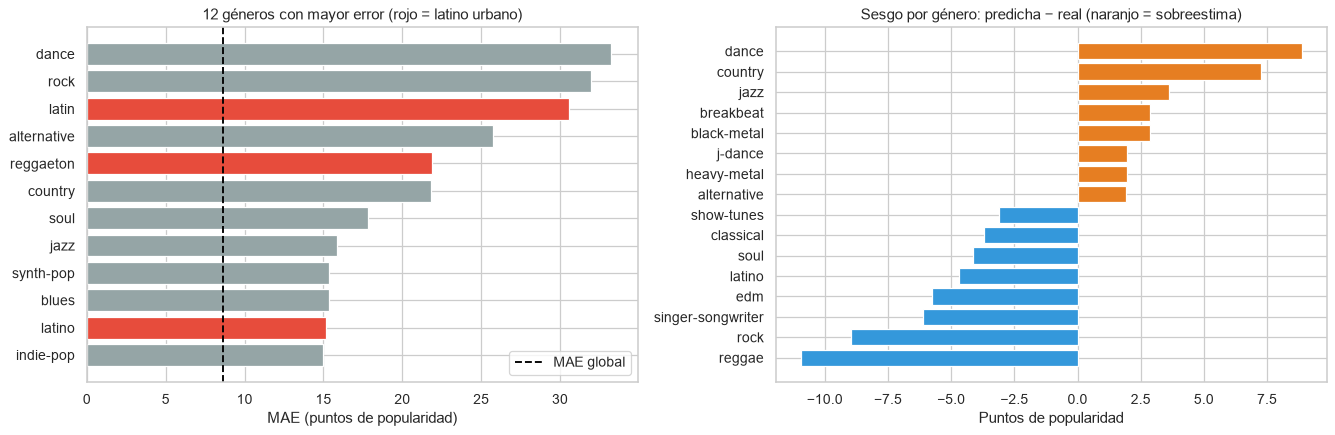

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
top_mae = por_genero.sort_values("MAE", ascending=False).head(12)
colores = ["#E74C3C" if g in LATINO_URBANO else "#95A5A6" for g in top_mae.index]
axes[0].barh(top_mae.index[::-1], top_mae["MAE"][::-1], color=colores[::-1])
axes[0].axvline((df["pop"] - df["pred_pop"]).abs().mean(), color="black", ls="--", label="MAE global")
axes[0].set_title("12 géneros con mayor error (rojo = latino urbano)")
axes[0].set_xlabel("MAE (puntos de popularidad)")
axes[0].legend()

sesgo = por_genero["sesgo_pop"].sort_values()
extremos = pd.concat([sesgo.head(8), sesgo.tail(8)])
axes[1].barh(extremos.index, extremos.values,
             color=np.where(extremos.values > 0, "#E67E22", "#3498DB"))
axes[1].set_title("Sesgo por género: predicha − real (naranjo = sobreestima)")
axes[1].set_xlabel("Puntos de popularidad")
plt.tight_layout()
plt.show()

**El sesgo de los datos pasa al modelo: el error se duplica en el grupo latino urbano.**

- En test hay 148 canciones de los géneros latin, latino, reggaeton y reggae. Su MAE es **19.7 puntos, 2.3 veces el del resto (8.5)**, y el modelo las **subestima en 4.6 puntos** en promedio.
- Su Recall es mayor (92% contra 81%) porque, al excluir `popularity = 0`, las canciones latinas que quedan son muy populares (media 49.6 contra 37.3). El modelo acierta que serán hit, pero no cuánto.
- Los géneros con más error (dance, rock, latin, alternative) son amplios y tienen pocas canciones en test (26 a 53): conviven éxitos masivos con canciones de nicho, y el género solo no los distingue.
- **Consecuencia:** las predicciones para música urbana latina no deben usarse sin revisión humana. **Mitigación propuesta:** unificar latin, latino, reggaeton y reggae y reconstruir esos géneros con las versiones originales de cada canción.

## 5. Selección de la solución analítica óptima

El mejor modelo no es solo el de mejor métrica: también debe ser **estable**, **generalizar** y ser **operable**
(tamaño y velocidad de predicción para puntuar un catálogo completo).

In [21]:
def costo(nombre_archivo, modelo, X):
    t0 = time.perf_counter()
    modelo.predict(X)
    ms = (time.perf_counter() - t0) / len(X) * 1000 * 1000
    return {"MB": (MODELS / nombre_archivo).stat().st_size / 1e6, "ms por 1.000 canciones": ms}

candidatos_clf = {"LogisticRegression": "logistic_regression_clf", "RandomForest": "random_forest_clf",
                  "GradientBoosting": "gradient_boosting_clf", "Voting": "voting_clf", "Stacking": "stacking_clf"}
filas = []
for nombre, ds in candidatos_clf.items():
    m = catalog.load(ds)
    fila = {"Modelo": nombre}
    fila.update(clf.set_index("Modelo").loc[nombre, ["F1", "ROC_AUC", "Precision", "Recall"]].to_dict())
    fila.update(gen_clf.set_index("Modelo").loc[nombre, ["Brecha_F1", "Diagnostico"]].to_dict())
    fila["F1_cv_std"] = cv_clf.set_index("Modelo").loc[nombre, "f1_std"]
    fila.update(costo(f"{ds}.joblib", m, X_test))
    filas.append(fila)
seleccion_clf = pd.DataFrame(filas).round(4)
seleccion_clf

[11/23/26 23:08:34] INFO     Loading data from logistic_regression_clf (PickleDataset)...      ]8;id=365222;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=365223;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

                    INFO     Loading data from random_forest_clf (PickleDataset)...            ]8;id=365228;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=365229;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

[11/23/26 23:08:35] INFO     Loading data from gradient_boosting_clf (PickleDataset)...        ]8;id=365234;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=365235;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

[11/23/26 23:08:36] INFO     Loading data from voting_clf (PickleDataset)...                   ]8;id=365240;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=365241;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

[11/23/26 23:08:38] INFO     Loading data from stacking_clf (PickleDataset)...                 ]8;id=365246;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=365247;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

,Modelo,F1,ROC_AUC,Precision,Recall,Brecha_F1,Diagnostico,F1_cv_std,MB,ms por 1.000 canciones
0,LogisticRegression,0.6468,0.8612,0.5368,0.8135,-0.0019,generaliza bien,0.0028,0.0051,1.4236
1,RandomForest,0.6313,0.8572,0.5037,0.8456,0.0868,sobreajuste leve,0.0055,13.7629,16.5258
2,GradientBoosting,0.6796,0.8844,0.5837,0.8131,0.0786,sobreajuste leve,0.0038,2.9125,50.9395
3,Voting,0.6698,0.8794,0.5616,0.8296,0.0486,generaliza bien,0.0046,15.2388,74.8365
4,Stacking,0.6753,0.8836,0.5718,0.8246,0.0727,generaliza bien,0.0044,15.1502,52.8806


In [22]:
candidatos_reg = {"Ridge": "ridge_reg", "RandomForest": "random_forest_reg",
                  "GradientBoosting": "gradient_boosting_reg", "Voting": "voting_reg", "Stacking": "stacking_reg"}
filas = []
for nombre, ds in candidatos_reg.items():
    m = catalog.load(ds)
    fila = {"Modelo": nombre}
    fila.update(reg.set_index("Modelo").loc[nombre, ["MAE", "RMSE", "R2"]].to_dict())
    fila.update(gen_reg.set_index("Modelo").loc[nombre, ["Brecha_MAE", "Diagnostico"]].to_dict())
    fila["MAE_cv_std"] = cv_reg.set_index("Modelo").loc[nombre, "MAE_std"]
    fila.update(costo(f"{ds}.joblib", m, X_test))
    filas.append(fila)
seleccion_reg = pd.DataFrame(filas).round(4)
seleccion_reg

[11/23/26 23:08:39] INFO     Loading data from ridge_reg (PickleDataset)...                    ]8;id=365252;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=365253;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

                    INFO     Loading data from random_forest_reg (PickleDataset)...            ]8;id=365258;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=365259;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

[11/23/26 23:08:40] INFO     Loading data from gradient_boosting_reg (PickleDataset)...        ]8;id=365264;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=365265;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

[11/23/26 23:08:41] INFO     Loading data from voting_reg (PickleDataset)...                   ]8;id=365270;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=365271;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

[11/23/26 23:08:43] INFO     Loading data from stacking_reg (PickleDataset)...                 ]8;id=365276;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=365277;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

,Modelo,MAE,RMSE,R2,Brecha_MAE,Diagnostico,MAE_cv_std,MB,ms por 1.000 canciones
0,Ridge,9.1228,12.5474,0.5026,-0.1308,generaliza bien,0.0516,0.0048,2.0570
1,RandomForest,9.8225,13.1075,0.4572,1.0587,sobreajuste leve,0.0595,29.2693,28.7191
2,GradientBoosting,8.6539,12.1337,0.5349,0.7229,generaliza bien,0.0467,2.6822,27.6830
3,Voting,8.9998,12.2965,0.5223,0.5366,generaliza bien,0.0474,30.5785,63.1607
4,Stacking,8.6285,12.1155,0.5363,0.5488,generaliza bien,0.0478,30.5134,68.5527


In [23]:
# Valor de negocio del clasificador elegido: lift al promocionar el top N% de canciones
proba = modelo_clf.predict_proba(X_test)[:, 1]
tasa_base = y_clf.mean()
filas = []
for top in [0.05, 0.10, 0.20]:
    sel = proba >= np.quantile(proba, 1 - top)
    filas.append({"Promocionar top": f"{top:.0%}", "% que son hits": y_clf[sel].mean(),
                  "Lift vs azar": y_clf[sel].mean() / tasa_base,
                  "% de todos los hits capturados": y_clf[sel].sum() / y_clf.sum()})
print(f"Elegir al azar: {tasa_base:.1%} de hits")
pd.DataFrame(filas).style.format({"% que son hits": "{:.1%}", "Lift vs azar": "{:.2f}x",
                                  "% de todos los hits capturados": "{:.1%}"})

Elegir al azar: 26.6% de hits


,Promocionar top,% que son hits,Lift vs azar,% de todos los hits capturados
0,5%,91.0%,3.43x,17.1%
1,10%,85.0%,3.20x,32.0%
2,20%,73.9%,2.78x,55.7%


In [24]:
# KPI de negocio de la regresión: % de canciones estimadas a ±10 puntos
error = np.abs(y_reg.values - pred_reg)
print(f"Predicciones a ±10 puntos del valor real: {(error <= 10).mean():.1%}")
print(f"Error absoluto mediano: {np.median(error):.1f} puntos")

Predicciones a ±10 puntos del valor real: 68.9%
Error absoluto mediano: 6.1 puntos


**Solución elegida: Gradient Boosting, en clasificación y en regresión.**

| Criterio | Gradient Boosting | Stacking (el más cercano) |
|---|---|---|
| F1 / ROC-AUC (clasificación, test) | **0.680** / 0.884 | 0.675 / 0.884 |
| MAE / R² (regresión, test) | 8.65 / 0.535 | 8.63 / 0.536 |
| Estabilidad (desv. CV de F1 / MAE) | 0.004 / 0.047 | 0.004 / 0.048 |
| Tamaño (clasificación / regresión) | **2.9 / 2.7 MB** | 15.2 / 30.5 MB |
| Interpretación | Directa (importancia por permutación) | 3 modelos + un meta-modelo |

- En clasificación gana sin discusión. En regresión empata con Stacking: 0.03 puntos de diferencia, menos que la variación entre folds. Ante un empate técnico se elige el modelo **más simple**: 5 a 11 veces más liviano, más rápido de predecir (ver la tabla de arriba, medido en este equipo) y más fácil de explicar.
- **Valor de negocio del clasificador:** si se promociona el 10% de canciones con mayor probabilidad, **el 85% son hits** (3.2× el azar); con el 5%, el 91%.
- **Valor del regresor:** el 68.9% de las canciones se estima a ±10 puntos y el error mediano es de 6.1 puntos; sirve para estimar el rango (bajo, medio, alto), no el valor exacto.
- **Alternativa interpretable:** Logistic Regression (F1 0.647) predice en ~1 ms y sus coeficientes muestran la dirección de cada efecto; sirve para explicar, no para decidir.